# SVHN Digit Classification: Lightweight CNN Benchmark
**Deep Learning coursework, The British University in Egypt, 2026. Author: Ziad Ayman (lightweight-architecture track of a 4-person group project)**

Nine variants of **MobileNetV3, ShuffleNetV2 and SqueezeNet** (pretrained vs. from scratch, plus a dropout variant) trained on SVHN at 64×64 for 3 epochs on CPU, then compared on validation and **held-out test** accuracy vs. training time.

**Best result:** ShuffleNetV2 ×1.0, **93.5% test accuracy** in ~6 minutes of training.

> Every experiment in this notebook was trained in a single top-to-bottom run (24 Nov 2026). Place the SVHN `.mat` files in `./data/svhn` and `./svhn_dataset`, or let torchvision download them.

## 1. Setup and imports

In [1]:
# 1. SETUP & IMPORTS
import os
import copy
import time
import random
import numpy as np
import torch
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Ensure Reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Local directory for dataset
DATA_DIR = "./data/svhn"
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment initialized. Using device: {device}")

Environment initialized. Using device: cpu


## 2. SVHN dataset: loading and visualisation

Loading SVHN Dataset...


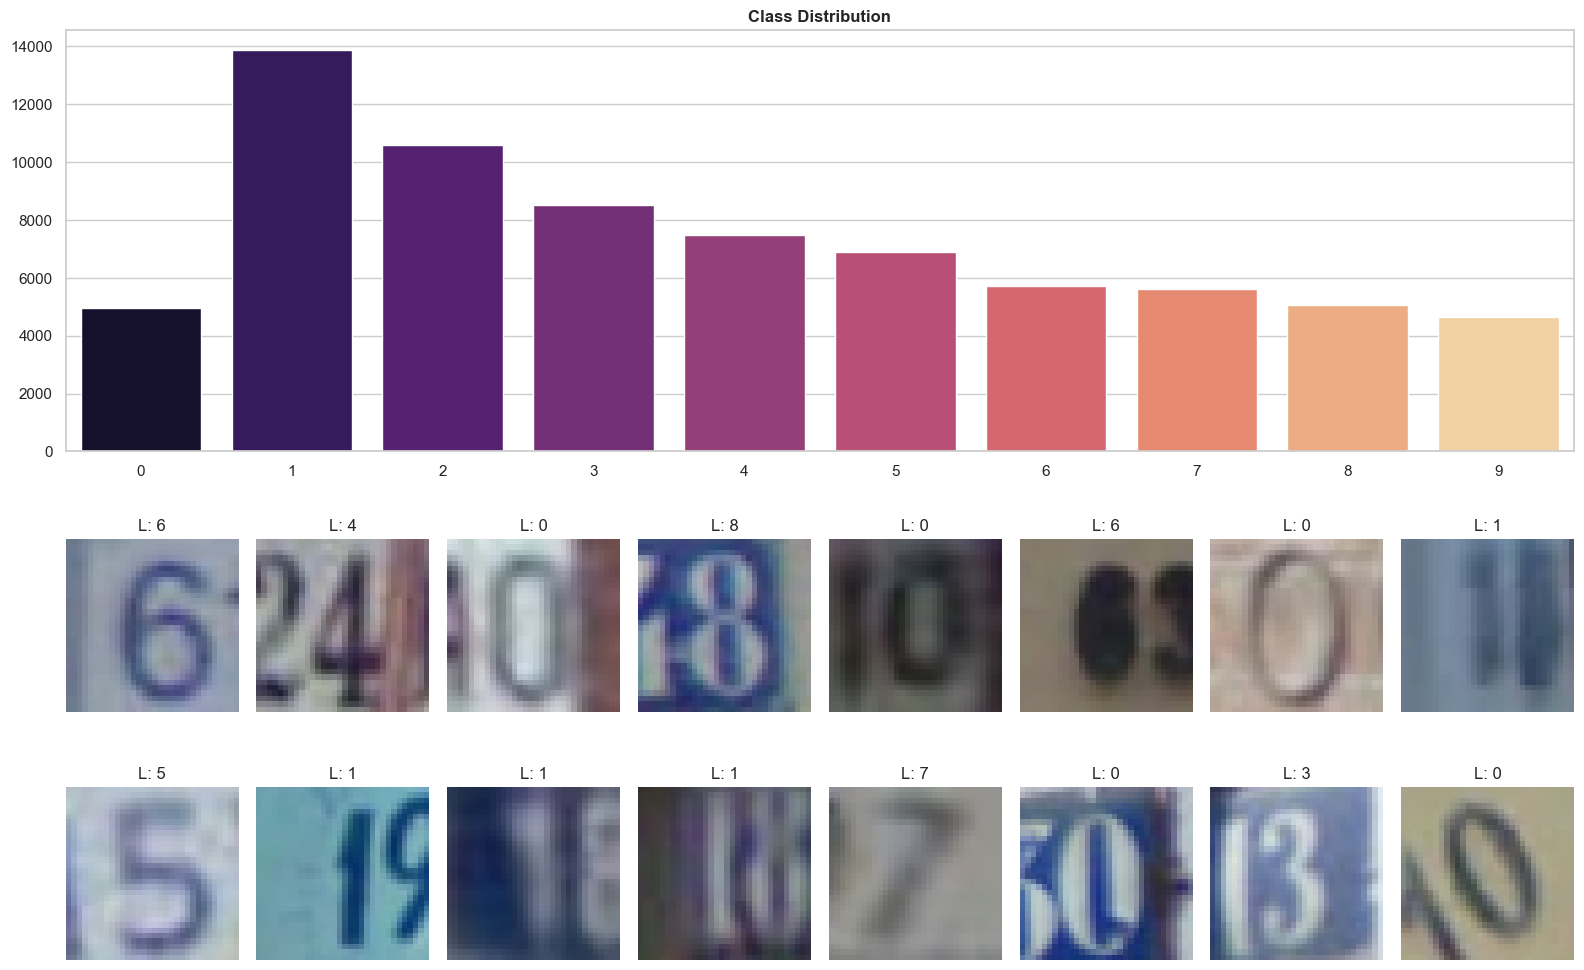

In [2]:
# 2. SVHN DATASET LOADING & VISUALIZATION
try:
    print(f"Loading SVHN Dataset...")
    svhn_train = torchvision.datasets.SVHN(root=DATA_DIR, split='train', download=True)
    labels = svhn_train.labels
    images = svhn_train.data # (N, 3, 32, 32)

    class_names = [str(i) for i in range(10)]
    class_counts = np.bincount(labels)

    sns.set_theme(style="whitegrid")
    fig = plt.figure(figsize=(16, 10))

    # Bar Plot
    ax1 = fig.add_subplot(2, 1, 1)
    sns.barplot(x=class_names, y=class_counts, hue=class_names, palette="magma", legend=False, ax=ax1)
    ax1.set_title("Class Distribution", fontweight='bold')

    # Sample Grid
    indices = np.random.choice(len(images), 16, replace=False)
    sample_imgs = np.transpose(images[indices], (0, 2, 3, 1))
    
    for i in range(16):
        plt.subplot(4, 8, i + 17)  # bottom half of a 4x8 grid
        plt.imshow(sample_imgs[i])
        plt.title(f"L: {labels[indices[i]]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"Error: {e}")

## 3. Transforms, class-weighted loss and DataLoaders (80/20 train/validation split + official test split)

In [3]:
# 3. TRANSFORMS & DATALOADERS
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# 64x64 is the "Sweet Spot" for SVHN speed vs accuracy
img_size = 64 

train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.437, 0.443, 0.472], std=[0.198, 0.201, 0.197])
])

test_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.437, 0.443, 0.472], std=[0.198, 0.201, 0.197])
])

# Load Datasets
DATA_DIR = "./svhn_dataset"
svhn_train = datasets.SVHN(root=DATA_DIR, split='train', transform=train_transform, download=True)
svhn_test = datasets.SVHN(root=DATA_DIR, split='test', transform=test_transform, download=True)

# 80/20 Split
train_size = int(0.8 * len(svhn_train))
val_size = len(svhn_train) - train_size
train_dataset, val_dataset = random_split(svhn_train, [train_size, val_size])

# Dataloaders - Using batch_size 128 to speed up training
dataloaders = {
    'train': DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=False),
    'val': DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=False),
    'test': DataLoader(svhn_test, batch_size=128, shuffle=False, num_workers=2, pin_memory=False)
}

# Criterion with your calculated weights
class_weights = torch.tensor([1.48, 0.52, 0.69, 0.86, 0.98, 1.06, 1.28, 1.31, 1.45, 1.57], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

print(f"Dataloaders ready at {img_size}x{img_size} resolution.")

Dataloaders ready at 64x64 resolution.


## 4. Model factory: MobileNetV3, ShuffleNetV2, SqueezeNet (with and without pretraining)

In [4]:
import torch
import torch.nn as nn
from torchvision import models

def get_model(name, variation):
    model = None
    
    # --- MODEL 1: MOBILENET V3 ---
    if name == "mobilenet":
        if variation == "small":
            model = models.mobilenet_v3_small(weights='DEFAULT')
        elif variation == "large":
            model = models.mobilenet_v3_large(weights='DEFAULT')
        elif variation == "small_no_pretrain":
            model = models.mobilenet_v3_small(weights=None) # Training from scratch
            
        # Adjusting the final layer for SVHN (10 classes)
        # MobileNetV3 uses a sequence in the classifier; index 3 is the final linear layer
        in_feats = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(in_feats, 10)
        
    # --- MODEL 2: SHUFFLENET V2 ---
    elif name == "shufflenet":
        if variation == "x0.5":
            model = models.shufflenet_v2_x0_5(weights='DEFAULT')
        elif variation == "x1.0":
            model = models.shufflenet_v2_x1_0(weights='DEFAULT')
        elif variation == "x0.5_no_pretrain":
            model = models.shufflenet_v2_x0_5(weights=None)
            
        in_feats = model.fc.in_features
        model.fc = nn.Linear(in_feats, 10)
        
    # --- MODEL 3: SQUEEZENET ---
    elif name == "squeezenet":
        if variation == "v1.1":
            model = models.squeezenet1_1(weights='DEFAULT')
        elif variation == "v1.0":
            model = models.squeezenet1_0(weights='DEFAULT')
        elif variation == "v1.1_dropout":
            model = models.squeezenet1_1(weights='DEFAULT')
            # Adding extra dropout to variation 3
            model.classifier[0] = nn.Dropout(p=0.5) 
            
        # SqueezeNet is unique: the last layer is a Conv2d, not a Linear layer
        model.classifier[1] = nn.Conv2d(512, 10, kernel_size=(1,1))
        model.num_classes = 10

    if model is None:
        raise ValueError(f"Model or variation '{variation}' not recognized.")

    return model.to(device)

# Sanity check: build one model
try:
    test_model = get_model("mobilenet", "small")
    print(f"Successfully loaded {test_model.__class__.__name__} to {device}")
except Exception as e:
    print(f"Model construction failed: {e}")

Successfully loaded MobileNetV3 to cpu


## 5. Training loop (keeps the best-validation checkpoint)

In [5]:
def train_model(model, model_name, dataloaders, criterion, optimizer, num_epochs=5):
    since = time.time()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    # SqueezeNet output handling (flattening if needed)
                    if isinstance(outputs, torch.Tensor) and outputs.dim() > 2:
                        outputs = torch.flatten(outputs, 1)
                    
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            epoch_loss = running_loss / len(dataloaders[phase].dataset)
            epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc.item())

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Val Acc: {best_acc:4f}')

    model.load_state_dict(best_model_wts)
    return model, history, time_elapsed

## 6. Results store

In [6]:
# Full re-run: every experiment (including MobileNetV3) is trained in this notebook.
results_log = {}
print("Starting fresh: all 9 experiments will be trained.")

Starting fresh: all 9 experiments will be trained.


## 7. Run all 9 experiments (3 epochs each) + held-out test-set evaluation

In [7]:
import torch.optim as optim
import time

# List of all 9 experiments
experiments = [
    ("mobilenet", "small"), ("mobilenet", "large"), ("mobilenet", "small_no_pretrain"),
    ("shufflenet", "x0.5"), ("shufflenet", "x1.0"), ("shufflenet", "x0.5_no_pretrain"),
    ("squeezenet", "v1.1"), ("squeezenet", "v1.0"), ("squeezenet", "v1.1_dropout")
]

for model_name, var in experiments:
    exp_name = f"{model_name}_{var}"
    
    # SKIP if we already have the results
    if exp_name in results_log:
        print(f">>> SKIPPING {exp_name} (Results already found)")
        continue
        
    print(f"\n>>> STARTING EXPERIMENT: {exp_name}")
    model = get_model(model_name, var)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    try:
        trained_model, history, duration = train_model(
            model, exp_name, dataloaders, criterion, optimizer, num_epochs=3
        )
        # Held-out test-set evaluation (official SVHN test split) of the best-val checkpoint
        trained_model.eval(); correct = total = 0
        with torch.no_grad():
            for inputs, labels in dataloaders['test']:
                inputs, labels = inputs.to(device), labels.to(device)
                out = trained_model(inputs)
                if out.dim() > 2: out = torch.flatten(out, 1)
                correct += (out.argmax(1) == labels).sum().item(); total += labels.size(0)
        test_acc = correct / total
        print(f"Test accuracy ({exp_name}): {test_acc:.4f}")
        results_log[exp_name] = {
            'history': history,
            'duration': duration,
            'best_val_acc': max(history['val_acc']),
            'test_acc': test_acc
        }
    except Exception as e:
        print(f"FAILED experiment {exp_name}: {e}")

print("\nALL REMAINING EXPERIMENTS COMPLETE.")


>>> STARTING EXPERIMENT: mobilenet_small
Epoch 1/3
----------


Train Loss: 0.7800 Acc: 0.7453


Val Loss: 0.4599 Acc: 0.8621
Epoch 2/3
----------


Train Loss: 0.3844 Acc: 0.8818


Val Loss: 0.3611 Acc: 0.8894
Epoch 3/3
----------


Train Loss: 0.3133 Acc: 0.9035


... (54 outputs left out)

Val Loss: 0.4656 Acc: 0.8567
Epoch 3/3
----------


Train Loss: 0.4340 Acc: 0.8689


Val Loss: 0.4743 Acc: 0.8582
Training complete in 5m 49s
Best Val Acc: 0.858176


Test accuracy (squeezenet_v1.1_dropout): 0.8756

ALL REMAINING EXPERIMENTS COMPLETE.


## 8. Comparison table and chart


==================== FINAL PROJECT COMPARISON ====================
               Model Variation Best Val Accuracy Test Accuracy  \
0              mobilenet_small            0.8965        0.9037   
1              mobilenet_large            0.9163        0.9246   
2  mobilenet_small_no_pretrain            0.8765        0.8845   
3              shufflenet_x0.5            0.8869        0.9067   
4              shufflenet_x1.0            0.9182        0.9345   
5  shufflenet_x0.5_no_pretrain            0.6992        0.7145   
6              squeezenet_v1.1            0.0788        0.0759   
7              squeezenet_v1.0            0.8968        0.9165   
8      squeezenet_v1.1_dropout            0.8582        0.8756   

  Total Time (sec) Avg Time per Epoch  
0           375.21             125.07  
1           925.76             308.59  
2           360.93             120.31  
3           231.20              77.07  
4           361.21             120.40  
5           234.23             

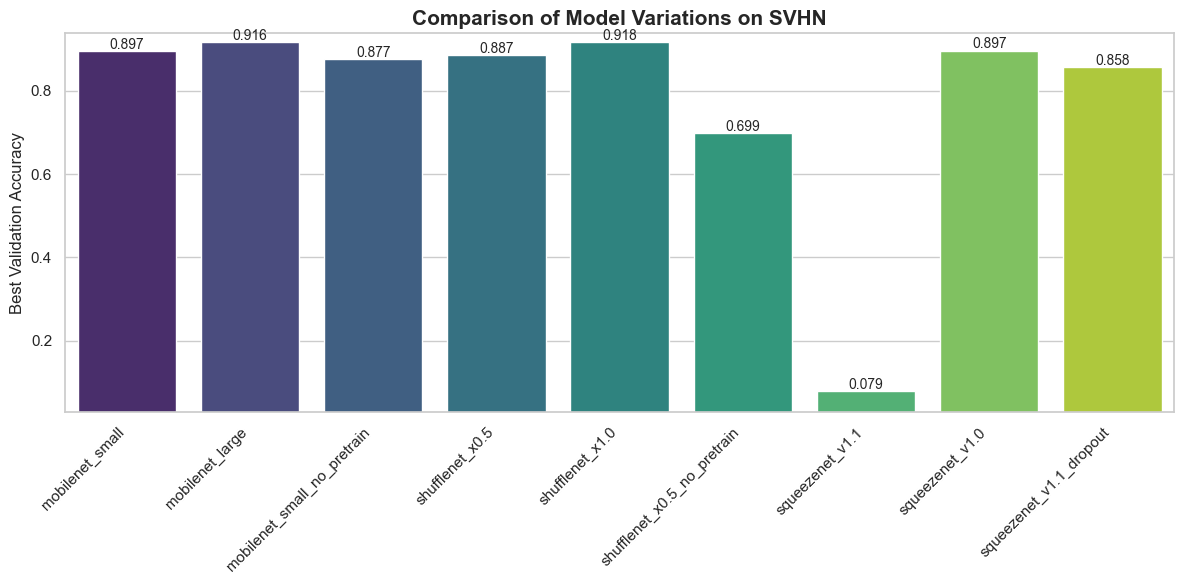


Results saved to 'svhn_model_comparison.csv'


In [8]:
import pandas as pd

# 1. Create a Comparison Table
stats_list = []
for name, data in results_log.items():
    stats_list.append({
        "Model Variation": name,
        "Best Val Accuracy": f"{data['best_val_acc']:.4f}",
        "Test Accuracy": f"{data.get('test_acc', float('nan')):.4f}",
        "Total Time (sec)": f"{data['duration']:.2f}",
        "Avg Time per Epoch": f"{(data['duration']/3):.2f}"
    })

df_results = pd.DataFrame(stats_list)
print("\n" + "="*20 + " FINAL PROJECT COMPARISON " + "="*20)
print(df_results)

# 2. Visualize Accuracy vs. Efficiency
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Plotting the best accuracy for each variation
names = list(results_log.keys())
accs = [data['best_val_acc'] for data in results_log.values()]

ax = sns.barplot(x=names, y=accs, palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Comparison of Model Variations on SVHN", fontsize=15, fontweight='bold')
plt.ylabel("Best Validation Accuracy")
plt.ylim(min(accs) - 0.05, max(accs) + 0.02) # Zoom in on the differences

# Add text labels on top of bars
for i, acc in enumerate(accs):
    ax.text(i, acc + 0.005, f'{acc:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# 3. Save results to a file for your report
df_results.to_csv("svhn_model_comparison.csv", index=False)
print("\nResults saved to 'svhn_model_comparison.csv'")